# Pembahasan UTS Praktikum CERTAN 2025 — Bahan Latihan

Mencakup Soal 1, Soal 2, serta kedua varian Soal 3 (NIM ganjil dan genap).

**STATUS: template solusi; belum dijalankan pada dataset ujian.** Tiga dataset belum tersedia dan belum terverifikasi publik. Dataset Pima teridentifikasi di sumber publik yang sesuai, tetapi belum tersalin ke paket ini karena koneksi unduh sandbox gagal. Tidak ada hasil model, metrik, maupun grafik yang dikarang.

Gunakan untuk belajar sebelum ujian. Dokumen ujian 2025 melarang internet dan AI saat pelaksanaan; ikuti aturan pengampu tentang bahan yang boleh dibawa, termasuk bahan yang disusun dengan bantuan AI.

## Dataset yang diperlukan

| Bagian | Nama berkas | Status |
|---|---|---|
| Soal 1 | users_data_cleaned.pickle | Memerlukan berkas asli dari e-course/pengampu |
| Soal 2 | Sales_Data.csv | Memerlukan berkas asli; nama sama tidak membuktikan isi sama |
| Soal 3 ganjil | pima-indians-diabetes.data.csv | Sumber publik cocok, 768 baris x 9 kolom, tanpa header |
| Soal 3 genap | konsumen.csv | Memerlukan berkas asli berkolom No, Gaji, Pengeluaran |

Simpan berkas dalam folder `datasets/` di sebelah notebook. Setiap bagian dapat dijalankan terpisah setelah sel persiapan. Jangan mengeksekusi pickle dari sumber yang tidak dipercaya: format pickle dapat menjalankan kode.

**Pima:** https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv

**Dokumentasi Pima:** https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.names

Unduh sebelum ujian dengan `python unduh_pima.py` atau melalui browser, bukan saat ujian.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path('datasets')  # ubah jika data disimpan di lokasi lain
OUT_DIR = Path('hasil')
OUT_DIR.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 15)

def data_path(name):
    path = DATA_DIR / name
    if not path.is_file():
        raise FileNotFoundError(f'{path} belum ada. Letakkan berkas asli pada folder datasets/.')
    return path

def clean_headers(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip().str.replace('\ufeff', '', regex=False)
    if df.columns.duplicated().any():
        raise ValueError('Nama kolom duplikat; periksa berkas asli.')
    return df

def require_columns(df, cols):
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise ValueError(f'Kolom tidak ditemukan: {missing}. Kolom aktual: {df.columns.tolist()}')

def numeric_checked(df, cols):
    out = df.copy()
    for c in cols:
        converted = pd.to_numeric(out[c], errors='coerce')
        invalid = out[c].notna() & converted.isna()
        if invalid.any():
            raise ValueError(f'{c}: ada teks nonnumerik. Periksa separator/desimal; jangan menebak satuan.')
        out[c] = converted
    if not np.isfinite(out[cols].to_numpy(dtype=float)).all():
        raise ValueError('Ada missing/infinite pada fitur numerik. Tentukan penanganan berdasarkan data asli.')
    return out

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT_DIR / name, dpi=150, bbox_inches='tight')
    plt.show()

print('Persiapan selesai. Folder data:', DATA_DIR.resolve())


Persiapan selesai. Folder data: C:\Users\Oktovaaaaa\Documents\GitHub\certan\Praktikum_CERTAN_UTS\datasets


## Soal 1 — Eksplorasi dan visualisasi (30 poin)

Setiap sel berikut dipetakan ke nomor perintah pada soal. Nama `number_transaction` pada butir 9 kemungkinan salah ketik dari `number_transactions`; kode menangani kedua nama dan menolak jika keduanya hadir sekaligus tanpa kepastian.

### 1. Load dan preview data
Jalankan sel ini hanya untuk pickle resmi yang dipercaya.


In [3]:
users = pd.read_pickle(data_path('users_data_cleaned.pickle'))
if not isinstance(users, pd.DataFrame):
    raise TypeError('Objek pickle bukan DataFrame. Periksa struktur berkas resmi.')
users = clean_headers(users)
if 'number_transaction' in users.columns and 'number_transactions' not in users.columns:
    users = users.rename(columns={'number_transaction': 'number_transactions'})
elif 'number_transaction' in users.columns and 'number_transactions' in users.columns:
    raise ValueError('Ada dua kolom transaksi; konfirmasikan kolom yang dimaksud.')
require_columns(users, ['age', 'number_transactions', 'date_joined', 'total_amount_usd', 'job', 'marital'])
display(users.head())


,user_id,number_transactions,total_amount_usd,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,term_deposit,date_joined,device
0,9231c446-cb16-4b2b-a7f7-ddfc8b25aaf6,3.0,2143.0,58,management,married,tertiary,False,True,False,None,261,1,-1,0,None,False,1998-08-23,mobile
1,bb92765a-08de-4963-b432-496524b39157,NaN,NaN,44,technician,single,secondary,False,True,False,None,151,1,-1,0,None,False,2008-07-15,desktop
2,573de577-49ef-42b9-83da-d3cfb817b5c1,2.0,2.0,33,entrepreneur,married,secondary,False,True,True,None,76,1,-1,0,None,False,2002-06-04,mobile
3,d6b66b9d-7c8f-4257-a682-e136f640b7e3,NaN,NaN,47,blue-collar,married,None,False,True,False,None,92,1,-1,0,None,False,1995-06-29,tablet
4,fade0b20-7594-4d9a-84cd-c02f79b1b526,1.0,1.0,33,None,single,None,False,False,False,None,198,1,-1,0,None,False,1995-08-01,mobile


### 2. Shape data


In [4]:
print('Shape:', users.shape)
print('Jumlah baris:', users.shape[0])
print('Jumlah kolom:', users.shape[1])


Shape: (45209, 19)
Jumlah baris: 45209
Jumlah kolom: 19


### 3. Tipe data


In [5]:
display(users.dtypes.rename('dtype').to_frame())
users.info()


,dtype
user_id,object
number_transactions,float64
total_amount_usd,float64
age,int64
job,object
...,...
previous,int64
poutcome,object
term_deposit,bool
date_joined,datetime64[ns]


<class 'pandas.DataFrame'>
Index: 45209 entries, 0 to 45215
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   user_id              45209 non-null  object        
 1   number_transactions  35210 non-null  float64       
 2   total_amount_usd     35210 non-null  float64       
 3   age                  45209 non-null  int64         
 4   job                  44921 non-null  object        
 5   marital              45209 non-null  object        
 6   education            43352 non-null  object        
 7   default              45209 non-null  bool          
 8   housing              45209 non-null  bool          
 9   loan                 45209 non-null  bool          
 10  contact              32191 non-null  object        
 11  duration             45209 non-null  int64         
 12  campaign             45209 non-null  int64         
 13  pdays                45209 non-null  int64     

### 4. Korelasi — hanya kolom numerik


In [6]:
users_num = users.select_dtypes(include='number')
if users_num.empty:
    raise ValueError('Tidak ada kolom numerik. Periksa tipe data sebelum menghitung korelasi.')
corr = users_num.corr(method='pearson')
display(corr)
corr.to_csv(OUT_DIR / 'soal1_korelasi.csv')


,number_transactions,total_amount_usd,age,duration,campaign,pdays,previous
number_transactions,1.000000,-0.163409,-0.008813,-0.017220,0.026431,-0.030751,-0.023046
total_amount_usd,-0.163409,1.000000,0.095839,0.022586,-0.017274,0.006435,0.016952
age,-0.008813,0.095839,1.000000,-0.004645,0.004767,-0.023745,0.001297
duration,-0.017220,0.022586,-0.004645,1.000000,-0.084551,-0.001549,0.001213
campaign,0.026431,-0.017274,0.004767,-0.084551,1.000000,-0.088636,-0.032860
pdays,-0.030751,0.006435,-0.023745,-0.001549,-0.088636,1.000000,0.454817
previous,-0.023046,0.016952,0.001297,0.001213,-0.032860,0.454817,1.000000


### 5. Statistik deskriptif numerik


In [7]:
display(users_num.describe())


,number_transactions,total_amount_usd,age,duration,campaign,pdays,previous
count,35210.000000,35210.000000,45209.000000,45209.000000,45209.000000,45209.000000,45209.000000
mean,3.977052,1369.417751,40.935853,258.153067,2.763897,40.199651,0.580349
std,3.814329,3063.412688,10.618653,257.525446,3.098076,100.130586,2.303489
min,1.000000,-8019.000000,18.000000,0.000000,1.000000,-1.000000,0.000000
25%,2.000000,73.000000,33.000000,103.000000,1.000000,-1.000000,0.000000
50%,3.000000,451.000000,39.000000,180.000000,2.000000,-1.000000,0.000000
75%,4.000000,1438.000000,48.000000,319.000000,3.000000,-1.000000,0.000000
max,20.000000,102127.000000,95.000000,4918.000000,63.000000,871.000000,275.000000


### 6. Histogram seluruh kolom numerik


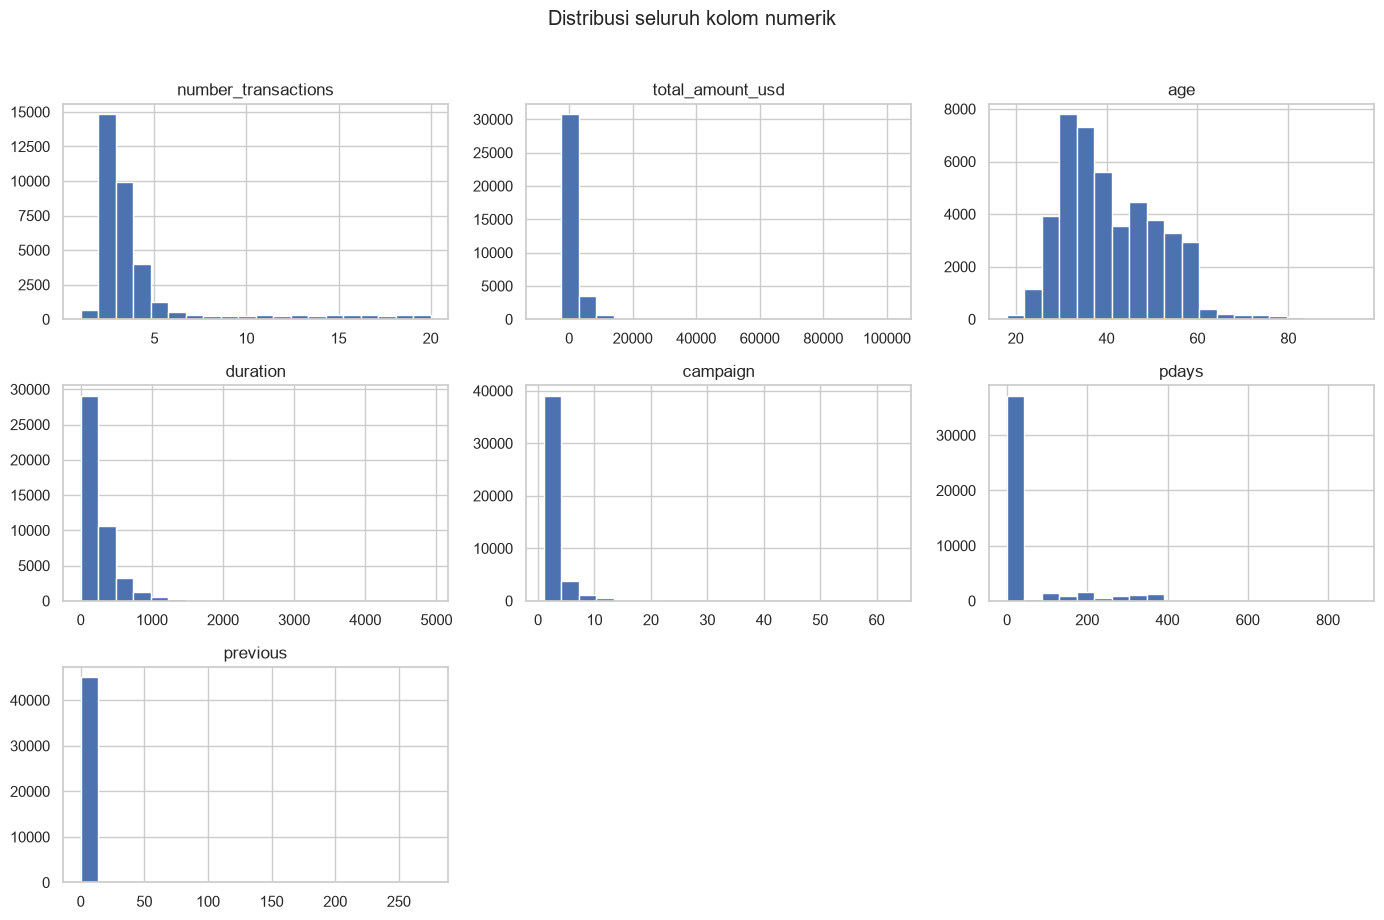

In [8]:
users_num.hist(bins=20, figsize=(14, max(4, 3 * int(np.ceil(len(users_num.columns) / 3)))), layout=(-1, 3))
plt.suptitle('Distribusi seluruh kolom numerik', y=1.02)
savefig('soal1_histogram.png')


### 7. Box plot age dan number_transactions — dipisah karena skala berbeda


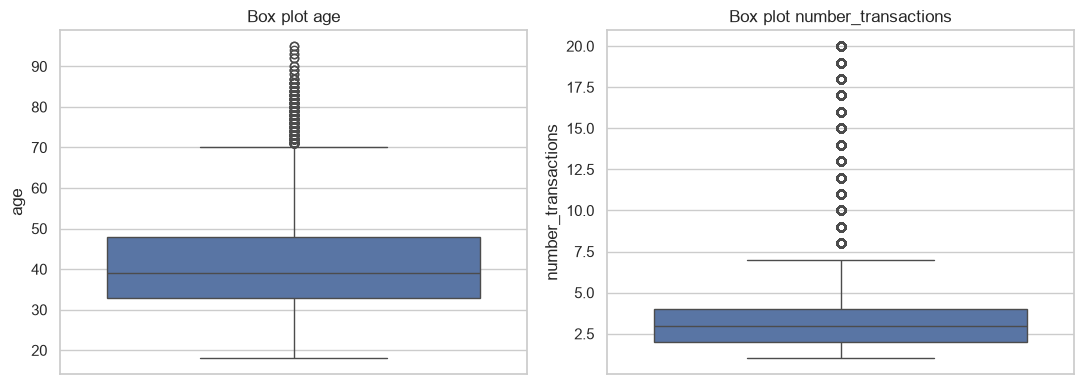

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=users, y='age', ax=axes[0])
sns.boxplot(data=users, y='number_transactions', ax=axes[1])
axes[0].set_title('Box plot age')
axes[1].set_title('Box plot number_transactions')
savefig('soal1_boxplot.png')


### 8. Line plot date_joined terhadap total_amount_usd
Tanggal dikonversi dan diurutkan. Jika beberapa pengguna memiliki tanggal bergabung yang sama, grafik berikut memakai **jumlah total_amount_usd per tanggal bergabung**. Ini profil cohort berdasarkan tanggal bergabung, bukan otomatis penjualan yang terjadi pada tanggal tersebut. Tanggal invalid dilaporkan, bukan disembunyikan.


Tanggal tidak terbaca/kosong: 30
Nilai amount kosong: 9999


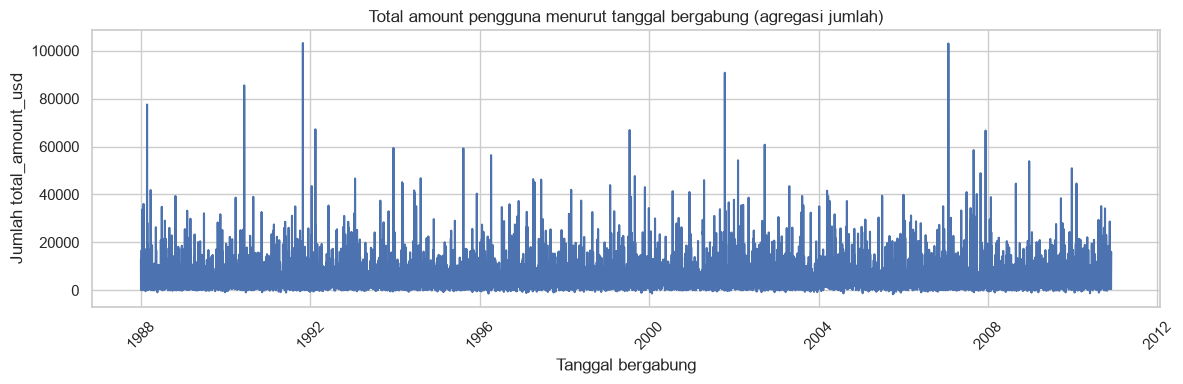

In [10]:
line_data = users[['date_joined', 'total_amount_usd']].copy()
line_data['date_joined'] = pd.to_datetime(line_data['date_joined'], errors='coerce')
print('Tanggal tidak terbaca/kosong:', int(line_data['date_joined'].isna().sum()))
print('Nilai amount kosong:', int(line_data['total_amount_usd'].isna().sum()))
line_data = line_data.dropna(subset=['date_joined', 'total_amount_usd'])
line_data['tanggal'] = line_data['date_joined'].dt.normalize()
daily = line_data.groupby('tanggal', as_index=False)['total_amount_usd'].sum().sort_values('tanggal')
plt.figure(figsize=(12, 4))
sns.lineplot(data=daily, x='tanggal', y='total_amount_usd', estimator=None)
plt.title('Total amount pengguna menurut tanggal bergabung (agregasi jumlah)')
plt.xlabel('Tanggal bergabung')
plt.ylabel('Jumlah total_amount_usd')
plt.xticks(rotation=45)
savefig('soal1_lineplot.png')


### 9. Scatter plot total_amount_usd dan number_transactions


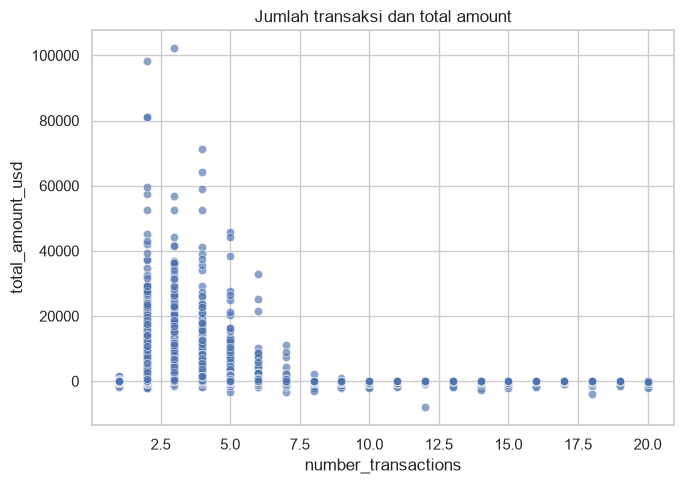

In [11]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=users, x='number_transactions', y='total_amount_usd', alpha=0.65)
plt.title('Jumlah transaksi dan total amount')
savefig('soal1_scatter.png')


### 10. Horizontal bar chart job — frekuensi pengguna


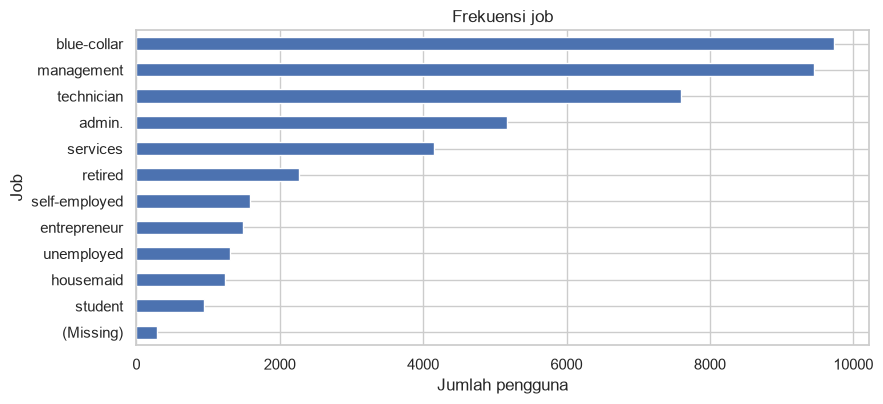

In [12]:
job_counts = users['job'].astype('string').fillna('(Missing)').value_counts().sort_values()
plt.figure(figsize=(9, max(4, 0.35 * len(job_counts))))
job_counts.plot.barh()
plt.xlabel('Jumlah pengguna')
plt.ylabel('Job')
plt.title('Frekuensi job')
savefig('soal1_job.png')


### 11. Horizontal bar chart marital — frekuensi pengguna


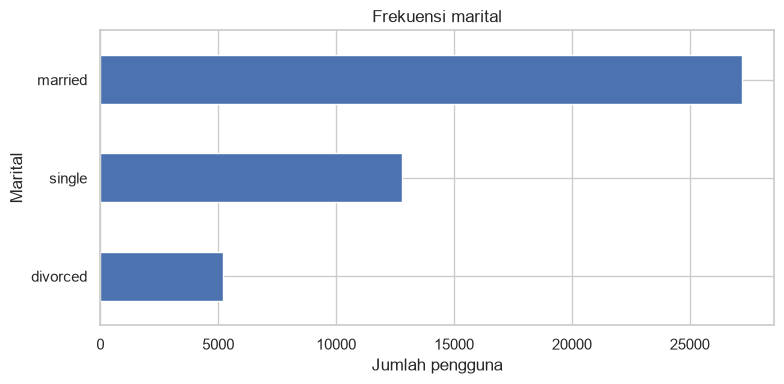

In [13]:
marital_counts = users['marital'].astype('string').fillna('(Missing)').value_counts().sort_values()
plt.figure(figsize=(8, 4))
marital_counts.plot.barh()
plt.xlabel('Jumlah pengguna')
plt.ylabel('Marital')
plt.title('Frekuensi marital')
savefig('soal1_marital.png')


### 12. Heatmap korelasi fitur — “future correlations” ditafsirkan sebagai “feature correlations”


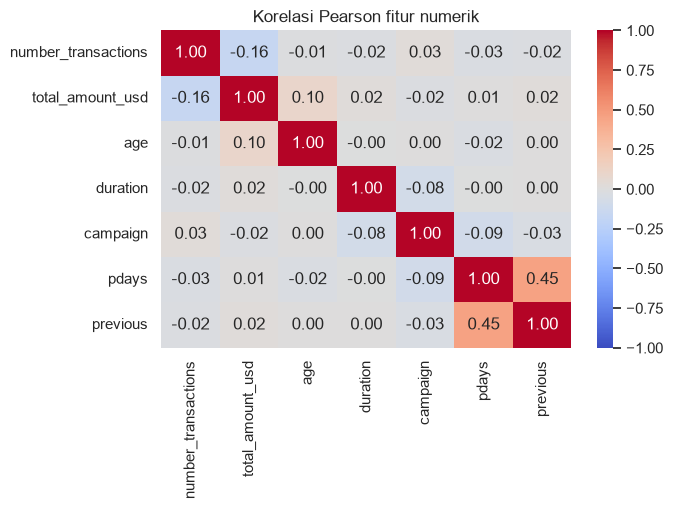

In [14]:
plt.figure(figsize=(max(7, len(corr) * 0.9), max(5, len(corr) * 0.75)))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Korelasi Pearson fitur numerik')
savefig('soal1_heatmap.png')


### 13. Identifikasi missing values


In [15]:
missing = pd.DataFrame({
    'jumlah_missing': users.isna().sum(),
    'persen_missing': users.isna().mean() * 100
}).sort_values('jumlah_missing', ascending=False)
display(missing)
print('Jumlah baris dengan minimal satu missing:', int(users.isna().any(axis=1).sum()))
missing.to_csv(OUT_DIR / 'soal1_missing.csv')


,jumlah_missing,persen_missing
poutcome,36957,81.746997
contact,13018,28.795151
number_transactions,9999,22.117278
total_amount_usd,9999,22.117278
education,1857,4.107589
...,...,...
duration,0,0.000000
previous,0,0.000000
pdays,0,0.000000
campaign,0,0.000000


Jumlah baris dengan minimal satu missing: 39105


## Soal 2 — LinearRegression (35 poin)

**Ambiguitas soal:** kalimat pembuka meminta prediksi biaya promosi, tetapi butir grafik f–g meminta penjualan berdasarkan biaya promosi. Implementasi utama mengikuti butir f–g: **X = Biaya Promo/Promosi, y = Nilai Penjualan**. Jika pengampu mengonfirmasi arah sebaliknya, ubah `ARAH` pada sel berikut, lalu jalankan ulang bagian Soal 2. Model terbalik harus dilatih ulang; bukan sekadar membalik persamaan.

### 1a–b. Membaca file dan menampilkan variabel
Nama header sebenarnya belum diketahui. Kode hanya menerima alias yang relevan dan berhenti jika ambigu. Periksa `sales.columns` dan atur nama secara eksplisit jika perlu. Jangan mengganti file ini dengan Salary_Data atau file penjualan lain yang tidak memiliki variabel sesuai.


In [16]:
sales = clean_headers(pd.read_csv(data_path('Sales_Data.csv'), sep=None, engine='python'))
display(sales.head())
print('Variabel:', sales.columns.tolist())
display(sales.dtypes)

def pick_column(columns, aliases):
    normalize = lambda s: ''.join(c for c in str(s).casefold() if c.isalnum())
    valid = {normalize(a) for a in aliases}
    matches = [c for c in columns if normalize(c) in valid]
    if len(matches) != 1:
        raise ValueError(f'Kolom ambigu/tidak ditemukan untuk {aliases}. Atur nama kolom sesuai berkas asli: {list(columns)}')
    return matches[0]

PROMO_COL = pick_column(sales.columns, ['Biaya Promo', 'Biaya Promosi'])
SALES_COL = pick_column(sales.columns, ['Nilai Penjualan', 'Penjualan'])
sales = numeric_checked(sales, [PROMO_COL, SALES_COL])
ARAH = 'penjualan_dari_promosi'
if ARAH == 'penjualan_dari_promosi':
    X_COL, Y_COL = PROMO_COL, SALES_COL
elif ARAH == 'promosi_dari_penjualan':
    X_COL, Y_COL = SALES_COL, PROMO_COL
else:
    raise ValueError('ARAH tidak dikenal')
X_sales = sales[[X_COL]]  # 2 dimensi untuk sklearn
Y_sales = sales[Y_COL]   # 1 dimensi untuk target
print('Prediktor X:', X_COL, '| Target y:', Y_COL)


,BiayaPromo,NilaiPenjualan
0,1500,90500
1,1800,89500
2,1900,105000
3,2050,102000
4,2050,90500


Variabel: ['BiayaPromo', 'NilaiPenjualan']


BiayaPromo        int64
NilaiPenjualan    int64
dtype: object

Prediktor X: BiayaPromo | Target y: NilaiPenjualan


### 1c. Split training 80% dan testing 20%


In [17]:
Xtr_sales, Xte_sales, ytr_sales, yte_sales = train_test_split(
    X_sales, Y_sales, test_size=0.20, random_state=SEED
)
train_sales = Xtr_sales.join(ytr_sales)
test_sales = Xte_sales.join(yte_sales)
print('Train:', Xtr_sales.shape, ytr_sales.shape)
print('Test :', Xte_sales.shape, yte_sales.shape)
display(train_sales)
display(test_sales)
train_sales.to_csv(OUT_DIR / 'soal2_train.csv', index=True)
test_sales.to_csv(OUT_DIR / 'soal2_test.csv', index=True)


Train: (16, 1) (16,)
Test : (4, 1) (4,)


,BiayaPromo,NilaiPenjualan
8,3050,152000
5,2100,104500
11,3500,174500
3,2050,102000
18,4100,204500
...,...,...
12,3500,150000
7,2400,150000
10,3200,153000
14,3750,187000


,BiayaPromo,NilaiPenjualan
0,1500,90500
17,4000,170500
15,3900,194500
1,1800,89500


### 1d–e. Membuat model, fit pada training, lalu predict testing


In [18]:
reg = LinearRegression()
reg.fit(Xtr_sales, ytr_sales)
yhat_sales = reg.predict(Xte_sales)
pred_sales = pd.DataFrame({
    X_COL: Xte_sales[X_COL],
    'aktual': yte_sales,
    'prediksi': yhat_sales,
    'residual': yte_sales - yhat_sales
})
with pd.option_context('display.max_rows', None):
    display(pred_sales)
pred_sales.to_csv(OUT_DIR / 'soal2_prediksi.csv', index=True)


,BiayaPromo,aktual,prediksi,residual
0,1500,90500,79244.654151,11255.345849
17,4000,170500,199104.607971,-28604.607971
15,3900,194500,194310.209818,189.790182
1,1800,89500,93627.848610,-4127.848610


### 1f. Grafik hubungan nilai penjualan dan biaya promosi


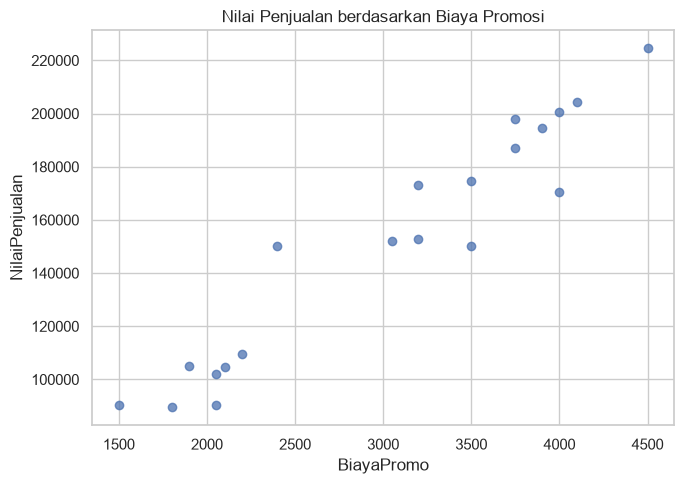

In [19]:
plt.figure(figsize=(7, 5))
plt.scatter(sales[PROMO_COL], sales[SALES_COL], alpha=0.75)
plt.xlabel(PROMO_COL)
plt.ylabel(SALES_COL)
plt.title('Nilai Penjualan berdasarkan Biaya Promosi')
savefig('soal2_hubungan.png')


### 1g. Garis prediksi pada training dan testing
Garis diurutkan melalui grid X agar tidak zigzag. Kedua panel menggunakan **model yang sama**, dilatih hanya pada training; tidak fit ulang pada test.


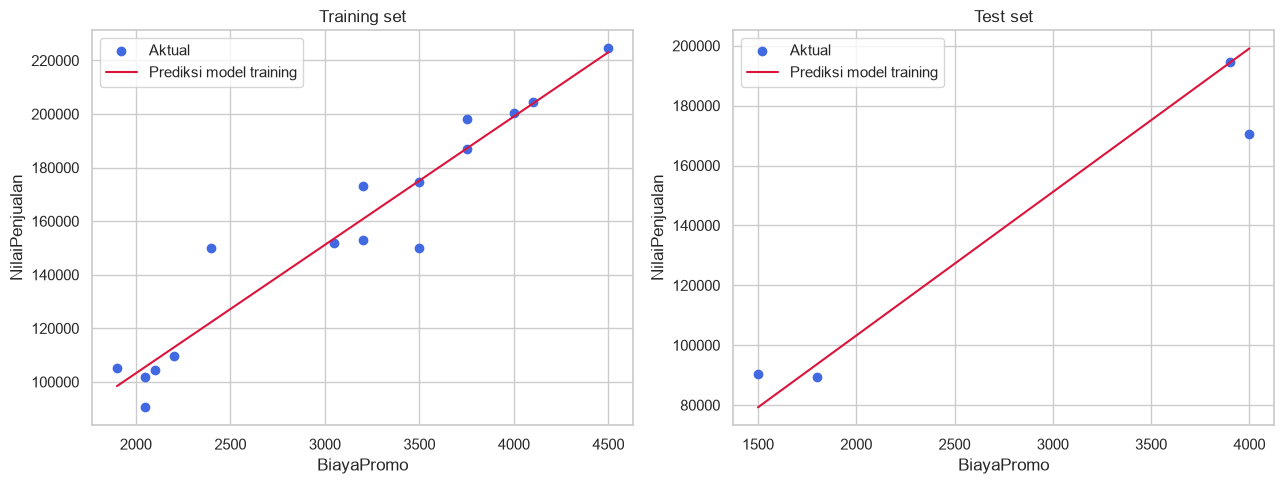

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, xx, yy, title in [
    (axes[0], Xtr_sales, ytr_sales, 'Training set'),
    (axes[1], Xte_sales, yte_sales, 'Test set')
]:
    ax.scatter(xx[X_COL], yy, color='royalblue', label='Aktual')
    grid = pd.DataFrame({X_COL: np.linspace(xx[X_COL].min(), xx[X_COL].max(), 100)})
    ax.plot(grid[X_COL], reg.predict(grid), color='crimson', label='Prediksi model training')
    ax.set(xlabel=X_COL, ylabel=Y_COL, title=title)
    ax.legend()
savefig('soal2_train_test_regresi.png')


### 2a–c. Intercept, slope, dan R-square
Untuk regresi sederhana: y_hat = intercept + slope * X. R-square test dapat negatif; nilainya bukan accuracy klasifikasi. Hasil dipengaruhi arah model, data, dan pembagian train/test.


In [21]:
print('Intercept:', reg.intercept_)
print('Slope:', reg.coef_[0])
print(f'Persamaan: {Y_COL} = {reg.intercept_:.6f} + ({reg.coef_[0]:.6f}) * {X_COL}')
print('R-square TRAIN:', reg.score(Xtr_sales, ytr_sales))
print('R-square TEST :', r2_score(yte_sales, yhat_sales) if len(yte_sales) >= 2 else 'Tidak terdefinisi: test kurang dari 2 sampel')
print('MSE TEST:', mean_squared_error(yte_sales, yhat_sales))


Intercept: 7328.681859251141
Slope: 47.94398152795902
Persamaan: NilaiPenjualan = 7328.681859 + (47.943982) * BiayaPromo
R-square TRAIN: 0.9247636876256119
R-square TEST : 0.8912369980143496
MSE TEST: 240495390.45314527


## Soal 3 — NIM Ganjil: K-NN diabetes (35 poin)

### 1–2. Membaca dataset dan menampilkan 8 baris teratas
Pima versi publik tidak memiliki header. Jika berkas resmi ternyata memiliki header, ubah parameter pembacaan dengan sengaja; jangan membuang baris data pertama tanpa memeriksa.

`class=0`: negatif pada dataset, `class=1`: positif. Ini latihan klasifikasi historis, bukan alat diagnosis klinis.


In [23]:
pima_names = ['preg', 'glukosa', 'pres', 'skin', 'insulin', 'BMI', 'pedi', 'age', 'class']
pima = pd.read_csv(data_path('pima-indians-diabetes.data.csv'))
pima = numeric_checked(pima, pima_names)
if not pima['class'].isin([0, 1]).all():
    raise ValueError('Label harus 0/1. Periksa apakah CSV memiliki header.')
pima['class'] = pima['class'].astype(int)
print('Shape:', pima.shape)
print('Distribusi kelas:', pima['class'].value_counts().sort_index().to_dict())
if pima.shape != (768, 9):
    print('PERHATIAN: ukuran berbeda dari versi publik 768 x 9. Periksa versi berkas.')
display(pima.head(8))


Shape: (768, 9)
Distribusi kelas: {0: 500, 1: 268}


,preg,glukosa,pres,skin,insulin,BMI,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0


### 3. Features dan label — 9 baris teratas


In [24]:
X_pima = pima.drop(columns='class')
y_pima = pima['class']
print('Features:')
display(X_pima.head(9))
print('Label:')
display(y_pima.head(9).to_frame())


Features:


,preg,glukosa,pres,skin,insulin,BMI,pedi,age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
5,5,116,74,0,0,25.6,0.201,30
6,3,78,50,32,88,31.0,0.248,26
7,10,115,0,0,0,35.3,0.134,29
8,2,197,70,45,543,30.5,0.158,53


Label:


,class
0,1
1,0
2,1
3,0
4,1
5,0
6,1
7,0
8,1


### 4. Split training 85% dan testing 15%
`stratify` mempertahankan proporsi kelas sejauh dimungkinkan. Untuk 768 data: 652 train dan 116 test karena ukuran test dibulatkan ke atas oleh sklearn.


In [25]:
Xtr_pima, Xte_pima, ytr_pima, yte_pima = train_test_split(
    X_pima, y_pima, test_size=0.15, random_state=SEED, stratify=y_pima
)
print('X_train:', Xtr_pima.shape, '| y_train:', ytr_pima.shape)
print('X_test :', Xte_pima.shape, '| y_test :', yte_pima.shape)
display(Xtr_pima.join(ytr_pima))
display(Xte_pima.join(yte_pima))
Xtr_pima.join(ytr_pima).to_csv(OUT_DIR / 'soal3_ganjil_train.csv')
Xte_pima.join(yte_pima).to_csv(OUT_DIR / 'soal3_ganjil_test.csv')


X_train: (652, 8) | y_train: (652,)
X_test : (116, 8) | y_test : (116,)


,preg,glukosa,pres,skin,insulin,BMI,pedi,age,class
110,3,171,72,33,135,33.3,0.199,24,1
594,6,123,72,45,230,33.6,0.733,34,0
732,2,174,88,37,120,44.5,0.646,24,1
323,13,152,90,33,29,26.8,0.731,43,1
561,0,198,66,32,274,41.3,0.502,28,1
...,...,...,...,...,...,...,...,...,...
213,0,140,65,26,130,42.6,0.431,24,1
113,4,76,62,0,0,34.0,0.391,25,0
556,1,97,70,40,0,38.1,0.218,30,0
254,12,92,62,7,258,27.6,0.926,44,1


,preg,glukosa,pres,skin,insulin,BMI,pedi,age,class
440,0,189,104,25,0,34.3,0.435,41,1
264,4,123,62,0,0,32.0,0.226,35,1
392,1,131,64,14,415,23.7,0.389,21,0
116,5,124,74,0,0,34.0,0.220,38,1
304,3,150,76,0,0,21.0,0.207,37,0
...,...,...,...,...,...,...,...,...,...
32,3,88,58,11,54,24.8,0.267,22,0
533,6,91,0,0,0,29.8,0.501,31,0
722,1,149,68,29,127,29.3,0.349,42,1
235,4,171,72,0,0,43.6,0.479,26,1


### 5–6. K=5, Euclidean distance, dan accuracy
Baseline berikut mengikuti algoritma yang diminta tanpa menambahkan perubahan data diam-diam. K-NN sensitif terhadap skala dan nilai nol tak-valid pada beberapa pengukuran Pima. Versi preprocessing terpisah diberikan di bawah; metriknya tidak harus sama dengan baseline.


In [26]:
knn5 = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn5.fit(Xtr_pima, ytr_pima)
pred_pima = knn5.predict(Xte_pima)
acc_pima = accuracy_score(yte_pima, pred_pima)
print(f'Accuracy K=5 baseline: {acc_pima:.4f} ({acc_pima:.2%})')
print('Confusion matrix:')
print(confusion_matrix(yte_pima, pred_pima))
print(classification_report(yte_pima, pred_pima, target_names=['Negatif', 'Positif'], zero_division=0))
display(pd.DataFrame({'aktual': yte_pima, 'prediksi': pred_pima}))


Accuracy K=5 baseline: 0.6638 (66.38%)
Confusion matrix:
[[58 18]
 [21 19]]
              precision    recall  f1-score   support

     Negatif       0.73      0.76      0.75        76
     Positif       0.51      0.47      0.49        40

    accuracy                           0.66       116
   macro avg       0.62      0.62      0.62       116
weighted avg       0.66      0.66      0.66       116



,aktual,prediksi
440,1,1
264,1,0
392,0,0
116,1,0
304,0,1
...,...,...
32,0,0
533,0,0
722,1,0
235,1,1


### 7. Grafik K terhadap accuracy, K=1 sampai 10
Untuk memenuhi grafik pada soal, accuracy test ditampilkan untuk setiap K. **Jangan menganggap K terbaik pada kurva test menghasilkan estimasi generalisasi yang bebas bias**, karena test sudah dipakai membandingkan model. Kolom CV dihitung hanya di training dan dapat digunakan untuk memilih K dengan lebih tepat.


,k,accuracy_test,accuracy_cv_train
0,1,0.689655,0.690135
1,2,0.715517,0.723876
2,3,0.681034,0.713188
3,4,0.732759,0.726952
4,5,0.663793,0.719248
5,6,0.724138,0.739201
6,7,0.706897,0.743793
7,8,0.706897,0.748385
8,9,0.698276,0.763688
9,10,0.698276,0.749924


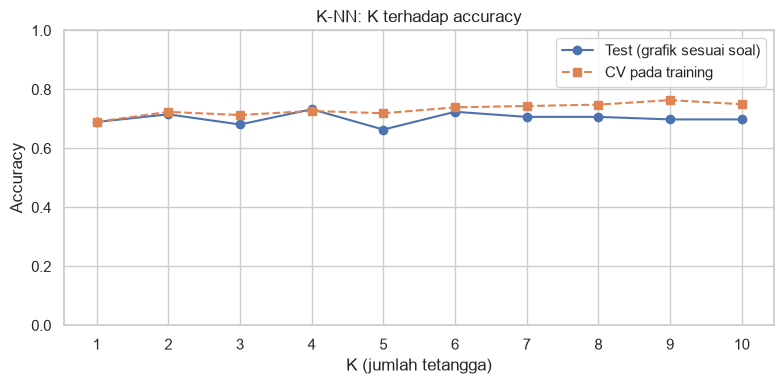

K terbaik menurut CV training: 9


In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
k_rows = []
for k in range(1, 11):
    m = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    cv_mean = cross_val_score(m, Xtr_pima, ytr_pima, cv=cv, scoring='accuracy').mean()
    m.fit(Xtr_pima, ytr_pima)
    k_rows.append({'k': k, 'accuracy_test': m.score(Xte_pima, yte_pima), 'accuracy_cv_train': cv_mean})
k_scores = pd.DataFrame(k_rows)
display(k_scores)
plt.figure(figsize=(8, 4))
plt.plot(k_scores['k'], k_scores['accuracy_test'], 'o-', label='Test (grafik sesuai soal)')
plt.plot(k_scores['k'], k_scores['accuracy_cv_train'], 's--', label='CV pada training')
plt.xticks(range(1, 11))
plt.xlabel('K (jumlah tetangga)')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.title('K-NN: K terhadap accuracy')
plt.legend()
savefig('soal3_ganjil_k_accuracy.png')
k_scores.to_csv(OUT_DIR / 'soal3_ganjil_k_accuracy.csv', index=False)
print('K terbaik menurut CV training:', int(k_scores.loc[k_scores['accuracy_cv_train'].idxmax(), 'k']))


### Tambahan pembelajaran — imputasi dan scaling yang benar
Nol pada `preg` dapat sah. Nol pada glukosa, tekanan darah, ketebalan kulit, insulin, dan BMI diperlakukan sebagai pengukuran hilang pada versi ini. Median dan scaling **fit hanya pada training** melalui pipeline. Jangan menyebut hasil ini identik dengan baseline.


In [28]:
zero_missing_cols = ['glukosa', 'pres', 'skin', 'insulin', 'BMI']
Xtr_clean = Xtr_pima.copy()
Xte_clean = Xte_pima.copy()
Xtr_clean[zero_missing_cols] = Xtr_clean[zero_missing_cols].replace(0, np.nan)
Xte_clean[zero_missing_cols] = Xte_clean[zero_missing_cols].replace(0, np.nan)
knn_preprocessed = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5, metric='euclidean'))
])
knn_preprocessed.fit(Xtr_clean, ytr_pima)
print('Accuracy K=5 setelah imputasi + scaling:', knn_preprocessed.score(Xte_clean, yte_pima))


Accuracy K=5 setelah imputasi + scaling: 0.75


## Soal 3 — NIM Genap: K-Means konsumen (35 poin)

Implementasi utama menggunakan dua fitur asli, seperti soal. Jika satuan atau skala berbeda jauh, scaling layak dipertimbangkan, tetapi hasil cluster akan berubah; jangan menerapkannya diam-diam saat ingin mereplikasi hasil modul.

### 1–2. Membaca konsumen.csv dan preview 7 baris


In [29]:
konsumen = clean_headers(pd.read_csv(data_path('konsumen.csv'), sep=None, engine='python'))
require_columns(konsumen, ['No', 'Gaji', 'Pengeluaran'])
display(konsumen.head(7))


,No,Gaji,Pengeluaran
0,1,2500,1750
1,2,3800,4200
2,3,3900,3800
3,4,4350,5500
4,5,4400,3200
5,6,5500,5450
6,7,5600,5950


### 3–4. Hapus No dan tampilkan 9 baris


In [30]:
konsumen = konsumen.drop(columns='No')
display(konsumen.head(9))
konsumen = numeric_checked(konsumen, ['Gaji', 'Pengeluaran'])
X_konsumen = konsumen[['Gaji', 'Pengeluaran']]
if len(X_konsumen.drop_duplicates()) < 2:
    raise ValueError('Minimal perlu dua titik unik untuk membentuk dua cluster.')


,Gaji,Pengeluaran
0,2500,1750
1,3800,4200
2,3900,3800
3,4350,5500
4,4400,3200
5,5500,5450
6,5600,5950
7,5750,4100
8,6850,6050


### 5. Grafik hubungan gaji dan pengeluaran


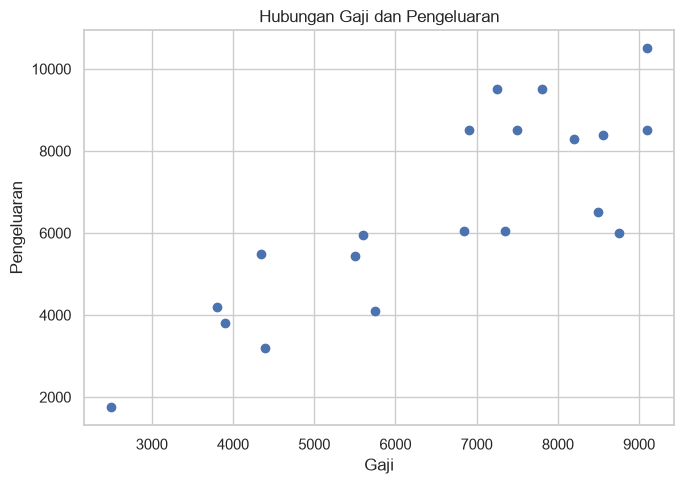

In [31]:
plt.figure(figsize=(7, 5))
plt.scatter(X_konsumen['Gaji'], X_konsumen['Pengeluaran'])
plt.xlabel('Gaji')
plt.ylabel('Pengeluaran')
plt.title('Hubungan Gaji dan Pengeluaran')
savefig('soal3_genap_hubungan.png')


### 6–7. Dua cluster dan pusat cluster


In [32]:
kmeans = KMeans(n_clusters=2, random_state=SEED, n_init=10)
cluster_labels = kmeans.fit_predict(X_konsumen)
centers = pd.DataFrame(kmeans.cluster_centers_, columns=['Gaji', 'Pengeluaran'])
centers.index.name = 'Cluster'
print('Pusat cluster (satuan asli):')
display(centers)
print('Inertia/WCSS:', kmeans.inertia_)
hasil_cluster = X_konsumen.assign(Cluster=cluster_labels)
display(hasil_cluster)
hasil_cluster.to_csv(OUT_DIR / 'soal3_genap_cluster.csv', index=False)
centers.to_csv(OUT_DIR / 'soal3_genap_centroid.csv')


Pusat cluster (satuan asli):


,Gaji,Pengeluaran
Cluster,,
0,4475.0,4243.75
1,7987.5,8025.00


Inertia/WCSS: 55100312.5


,Gaji,Pengeluaran,Cluster
0,2500,1750,0
1,3800,4200,0
2,3900,3800,0
3,4350,5500,0
4,4400,3200,0
...,...,...,...
15,8500,6500,1
16,8550,8400,1
17,8750,6000,1
18,9100,10500,1


### 8. Grafik konsumen dengan dua warna


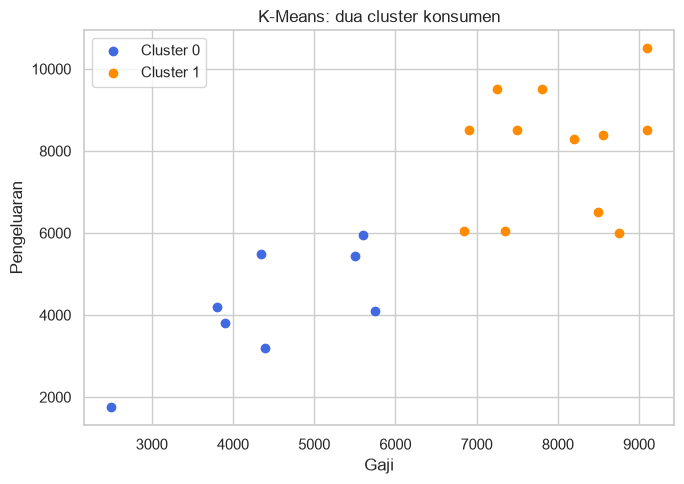

In [33]:
colors = ['royalblue', 'darkorange']
plt.figure(figsize=(7, 5))
for c in range(2):
    points = X_konsumen.loc[cluster_labels == c]
    plt.scatter(points['Gaji'], points['Pengeluaran'], color=colors[c], label=f'Cluster {c}')
plt.xlabel('Gaji')
plt.ylabel('Pengeluaran')
plt.title('K-Means: dua cluster konsumen')
plt.legend()
savefig('soal3_genap_cluster.png')


### 9. Grafik dua warna beserta pusat cluster


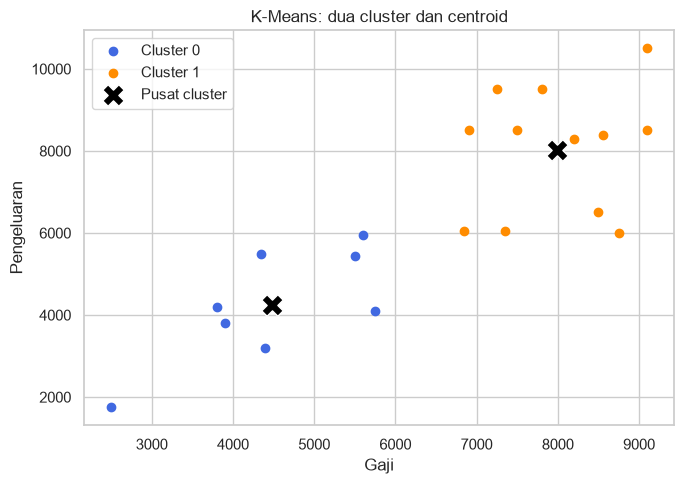

In [35]:
plt.figure(figsize=(7, 5))
for c in range(2):
    points = X_konsumen.loc[cluster_labels == c]
    plt.scatter(points['Gaji'], points['Pengeluaran'], color=colors[c], label=f'Cluster {c}')
plt.scatter(centers['Gaji'], centers['Pengeluaran'], marker='X', s=240,
            color='black', edgecolors='white', label='Pusat cluster')
plt.xlabel('Gaji')
plt.ylabel('Pengeluaran')
plt.title('K-Means: dua cluster dan centroid')
plt.legend()
savefig('soal3_genap_centroid.png')


## Interpretasi dan pemeriksaan akhir

- Label cluster 0 dan 1 tidak mempunyai makna urutan; penomorannya dapat bertukar.
- Intercept, slope, R-square, accuracy, centroid, dan grafik baru dapat disimpulkan setelah data asli dijalankan.
- Korelasi tidak membuktikan sebab-akibat. ID numerik bukan otomatis fitur analitis bermakna.
- Jangan menggunakan test set untuk melatih model maupun mempelajari parameter preprocessing.
- Jika CSV menggunakan desimal koma atau pemisah ribuan, periksa berkas mentah dan sesuaikan `sep`, `decimal`, atau `thousands` secara eksplisit.

## Menjalankan dan mengekspor

1. Instal dependensi sebelum ujian dengan `python -m pip install -r requirements.txt` jika belum tersedia.
2. Buka notebook dari folder paket dan lengkapi berkas dalam `datasets/`.
3. Jalankan sel persiapan, Soal 1, Soal 2, lalu varian Soal 3 sesuai NIM. Kedua varian disediakan untuk latihan, bukan kewajiban mengumpulkan keduanya.
4. Jika ingin Run All, hapus/lewati varian Soal 3 yang tidak dikerjakan dan pastikan seluruh dataset yang dirujuk tersedia.
5. Periksa output, simpan notebook, lalu export HTML dan Print to PDF melalui browser atau menu ekspor Jupyter yang tersedia. PDF panduan dalam paket bukan PDF hasil running.
6. Kumpulkan notebook yang sudah berisi output dan PDF hasilnya dalam `NIM_UTS_praktikum_Certan.zip` sesuai aturan pengampu. Paket latihan ini belum merupakan berkas pengumpulan final.

Petunjuk umum halaman 1 menyebut output notebook yang diekspor PDF cukup, meskipun rubrik masih menyebut screenshot. Ikuti klarifikasi pengampu bila berbeda.

## Latihan pemahaman

1. Mengapa X regresi ditulis `df[[nama_kolom]]`, bukan `df[nama_kolom]`?
2. Mengapa kolom No tidak dipakai untuk K-Means?
3. Mengapa scaler tidak boleh di-fit pada seluruh data sebelum split?
4. Mengapa file Pima harus dibaca dengan `header=None`?
5. Apa perbedaan `fit`, `predict`, dan `fit_predict`?
